# Question 1

In [1]:
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

from pathlib import Path

import cv2
import numpy as np

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents) if (p / "a2images").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root containing the a2images folder.")
IMAGE_DIR = PROJECT_ROOT / "a2images"
RESULTS_DIR = PROJECT_ROOT / "results"
print(f"Project root: {PROJECT_ROOT}")


Project root: C:\Users\Jaindu Samaranayaka\Documents\Semester_5\CV\fitting and alignment git


In [2]:
image_path = IMAGE_DIR / "the_berry_farms_sunflower_field.jpeg"
image_bgr = cv2.imread(str(image_path), cv2.IMREAD_REDUCED_COLOR_4)

if image_bgr is None:
    raise FileNotFoundError(f"Could not read image: {image_path.resolve()}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
print(f"Image dimensions: {gray.shape[1]} Ã— {gray.shape[0]} pixels")

Image dimensions: 360 Ã— 360 pixels


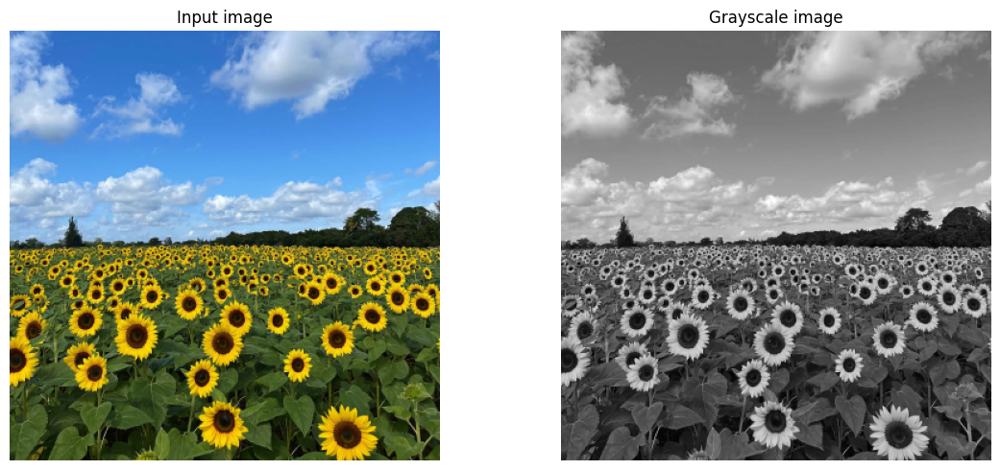

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image_rgb)
axes[0].set_title("Input image")
axes[0].axis("off")
axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale image")
axes[1].axis("off")
plt.tight_layout()

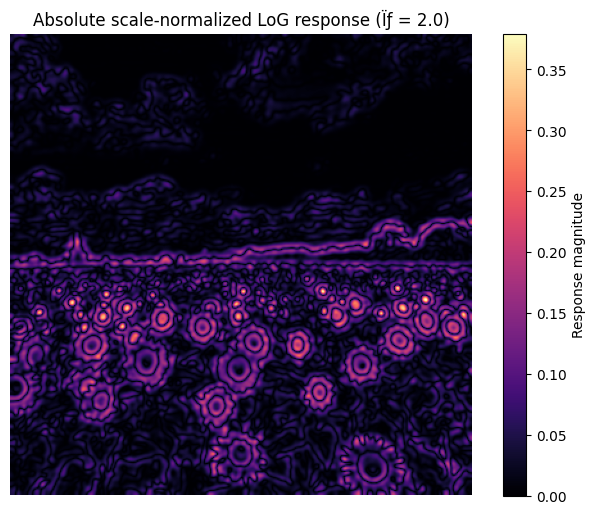

In [4]:
sigma = 2.0
gray_float = gray.astype(np.float32) / 255.0
smoothed = cv2.GaussianBlur(
    gray_float,
    ksize=(0, 0),
    sigmaX=sigma,
    sigmaY=sigma,
)
laplacian = cv2.Laplacian(smoothed, cv2.CV_32F)
log_response = sigma**2 * laplacian

plt.figure(figsize=(8, 6))
plt.imshow(np.abs(log_response), cmap="magma")
plt.title(f"Absolute scale-normalized LoG response (Ïƒ = {sigma})")
plt.axis("off")
plt.colorbar(label="Response magnitude")
plt.show()

Scale range: sigma = 1.50 to 12.00 px (18 scales)
Response threshold: 0.2236; detections: 64
Largest detections (x, y, sigma, radius, response):
( 187,  341), sigma= 5.10, r= 7.21, response=0.2599
( 167,  338), sigma= 5.10, r= 7.21, response=0.2460
( 300,  344), sigma= 5.10, r= 7.21, response=0.2430
(   0,  291), sigma= 4.51, r= 6.38, response=0.2635
( 164,  325), sigma= 4.51, r= 6.38, response=0.2526
( 268,  348), sigma= 4.51, r= 6.38, response=0.2520
( 190,  253), sigma= 4.51, r= 6.38, response=0.2420
( 295,  327), sigma= 4.51, r= 6.38, response=0.2279
( 112,  269), sigma= 3.99, r= 5.64, response=0.2916
(  13,  286), sigma= 3.99, r= 5.64, response=0.2752


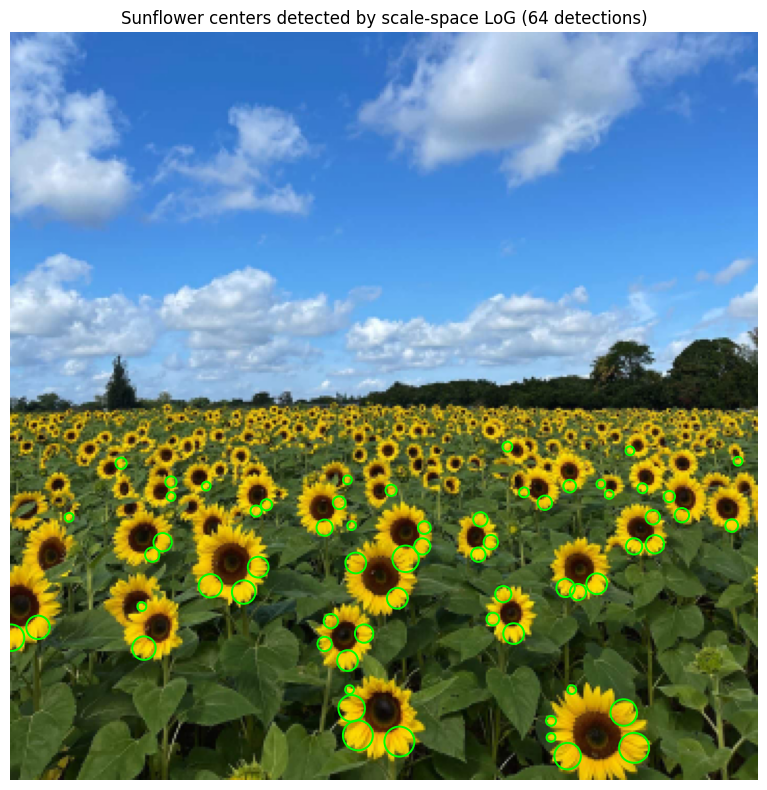

In [5]:
# Q1: Search the scale-normalized LoG volume for extrema in x, y, and scale.
# Report the scale interval and largest detected flower-center circles.
from scipy.ndimage import maximum_filter

# Search small-to-large flower centers at these scales (pixels in the reduced image).
sigmas = np.geomspace(1.5, 12.0, 18)
responses = []
for scale in sigmas:
    blurred = cv2.GaussianBlur(gray_float, (0, 0), sigmaX=float(scale), sigmaY=float(scale))
    # Sunflower centers are darker than their surroundings, so use -LoG.
    response = -(float(scale) ** 2) * cv2.Laplacian(blurred, cv2.CV_32F)
    responses.append(response)
scale_space = np.stack(responses, axis=0)

# Keep maxima across x, y and neighboring scales; suppress image-border artifacts.
local_max = scale_space == maximum_filter(scale_space, size=(3, 5, 5), mode="nearest")
positive = scale_space[scale_space > 0]
response_floor = max(float(np.quantile(positive, 0.997)), 0.025) if positive.size else 0.025
candidate_indices = np.argwhere(local_max & (scale_space >= response_floor))
# Restrict detections to the sunflower field and below, excluding sky and distant trees.
candidates = [
    (float(scale_space[k, y, x]), int(x), int(y), float(sigmas[k]), float(np.sqrt(2) * sigmas[k]))
    for k, y, x in candidate_indices
    if y >= int(0.50 * gray.shape[0])
]
candidates.sort(reverse=True)

# Greedy spatial non-maximum suppression keeps one circle per flower center.
detections = []
for score, x, y, scale, radius in candidates:
    if all((x - dx) ** 2 + (y - dy) ** 2 >= (1.4 * max(radius, dr)) ** 2
           for _, dx, dy, _, dr in detections):
        detections.append((score, x, y, scale, radius))
    if len(detections) >= 100:
        break

print(f"Scale range: sigma = {sigmas.min():.2f} to {sigmas.max():.2f} px ({len(sigmas)} scales)")
print(f"Response threshold: {response_floor:.4f}; detections: {len(detections)}")
print("Largest detections (x, y, sigma, radius, response):")
for score, x, y, scale, radius in sorted(detections, key=lambda item: item[4], reverse=True)[:10]:
    print(f"({x:4d}, {y:4d}), sigma={scale:5.2f}, r={radius:5.2f}, response={score:.4f}")

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image_rgb)
for score, x, y, scale, radius in detections:
    ax.add_patch(plt.Circle((x, y), radius, color="lime", fill=False, linewidth=1.4))
ax.set_title(f"Sunflower centers detected by scale-space LoG ({len(detections)} detections)")
ax.axis("off")
plt.tight_layout()
q1_output = RESULTS_DIR / "question_1"
q1_output.mkdir(parents=True, exist_ok=True)
fig.savefig(q1_output / "sunflower_log_detections.png", dpi=180, bbox_inches="tight")
plt.show()


# Question 2

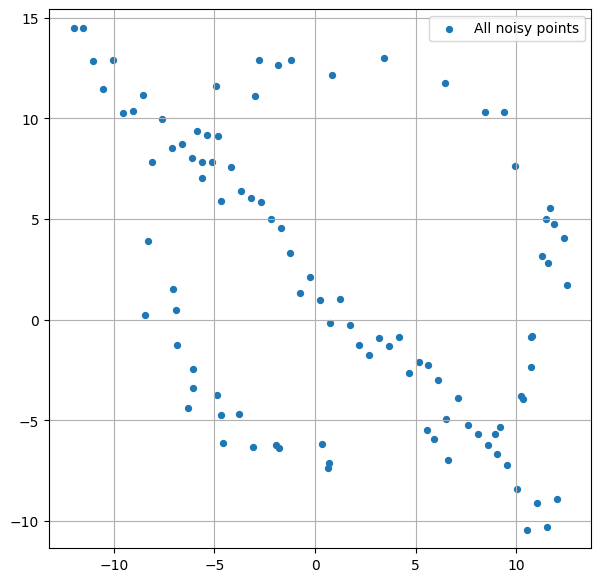

In [6]:
rng = np.random.default_rng(0)
N = 100
half_n = N // 2

# Noisy circle points (ground truth is useful for checking the plot later).
circle_radius_gt = 10.0
circle_center_gt = np.array([2.0, 3.0])
t = rng.uniform(0, 2 * np.pi, half_n)
radial_noise = (circle_radius_gt / 16) * rng.standard_normal(half_n)
X_circle = np.column_stack((
    circle_center_gt[0] + (circle_radius_gt + radial_noise) * np.cos(t),
    circle_center_gt[1] + (circle_radius_gt + radial_noise) * np.sin(t),
))

# Noisy line points.
line_slope_gt, line_intercept_gt = -1.0, 2.0
x_line = np.linspace(-12, 12, half_n)
y_line = line_slope_gt * x_line + line_intercept_gt + rng.standard_normal(half_n)
X_line = np.column_stack((x_line, y_line))
X = np.vstack((X_circle, X_line))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[:, 0], X[:, 1], s=18, label="All noisy points")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
ax.grid(True)
plt.show()

Line: 0.7044 x + 0.7098 y = 1.6010
Consensus points: 49 / 100
Two-point sample indices: [94 61]


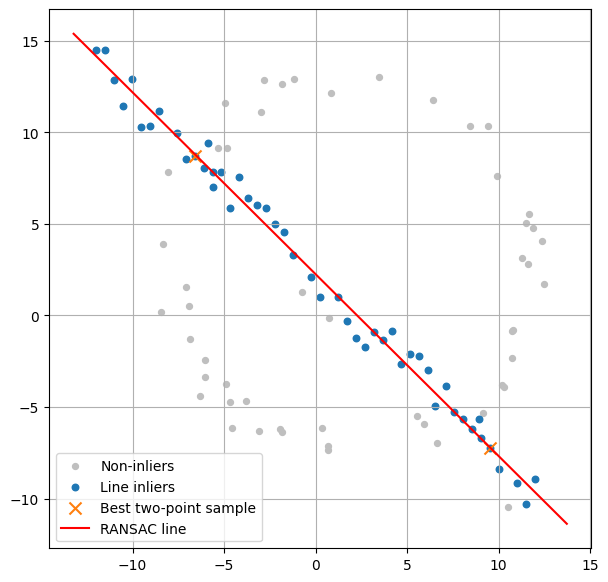

In [7]:
def line_from_two_points(p1, p2):
    """Return (a, b, d) for a unit-normal line a*x + b*y = d."""
    direction = p2 - p1
    length = np.linalg.norm(direction)
    if length < 1e-12:
        return None
    normal = np.array([-direction[1], direction[0]]) / length
    return normal[0], normal[1], float(normal @ p1)


def ransac_line(points, threshold=1.5, min_inliers=35, iterations=2000, seed=0):
    """Find a line with two-point RANSAC; return model, inlier mask, sample."""
    random = np.random.default_rng(seed)
    best_model, best_mask, best_sample = None, None, None
    for _ in range(iterations):
        sample = random.choice(len(points), size=2, replace=False)
        model = line_from_two_points(points[sample[0]], points[sample[1]])
        if model is None:
            continue
        a, b, d = model
        errors = np.abs(points @ np.array([a, b]) - d)
        mask = errors < threshold
        if best_mask is None or mask.sum() > best_mask.sum():
            best_model, best_mask, best_sample = model, mask, sample

    if best_mask is None or best_mask.sum() < min_inliers:
        raise RuntimeError("RANSAC did not find a line with enough consensus points.")

    # Refit using all consensus points with total least squares, preserving ||[a,b]||=1.
    inlier_points = points[best_mask]
    centroid = inlier_points.mean(axis=0)
    _, _, vh = np.linalg.svd(inlier_points - centroid, full_matrices=False)
    normal = vh[-1]
    d = float(normal @ centroid)
    return (float(normal[0]), float(normal[1]), d), best_mask, best_sample

line_model, line_inliers, line_sample = ransac_line(X, threshold=1.0, min_inliers=35)
a, b, d = line_model
print(f"Line: {a:.4f} x + {b:.4f} y = {d:.4f}")
print(f"Consensus points: {line_inliers.sum()} / {len(X)}")
print(f"Two-point sample indices: {line_sample}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[~line_inliers, 0], X[~line_inliers, 1], s=18, color="0.75", label="Non-inliers")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=22, label="Line inliers")
sample_points = X[line_sample]
ax.scatter(sample_points[:, 0], sample_points[:, 1], s=75, marker="x", label="Best two-point sample")
x_limits = np.array(ax.get_xlim())
if abs(b) > 1e-8:
    ax.plot(x_limits, (d - a * x_limits) / b, "r-", label="RANSAC line")
else:
    x_value = d / a
    ax.axvline(x_value, color="r", label="RANSAC line")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
ax.grid(True)
plt.show()

Circle: center=(2.186, 2.739), radius=9.959
Circle consensus: 39 / 51 line-removed points
Three-point sample indices in line-removed set: [28  5 29]


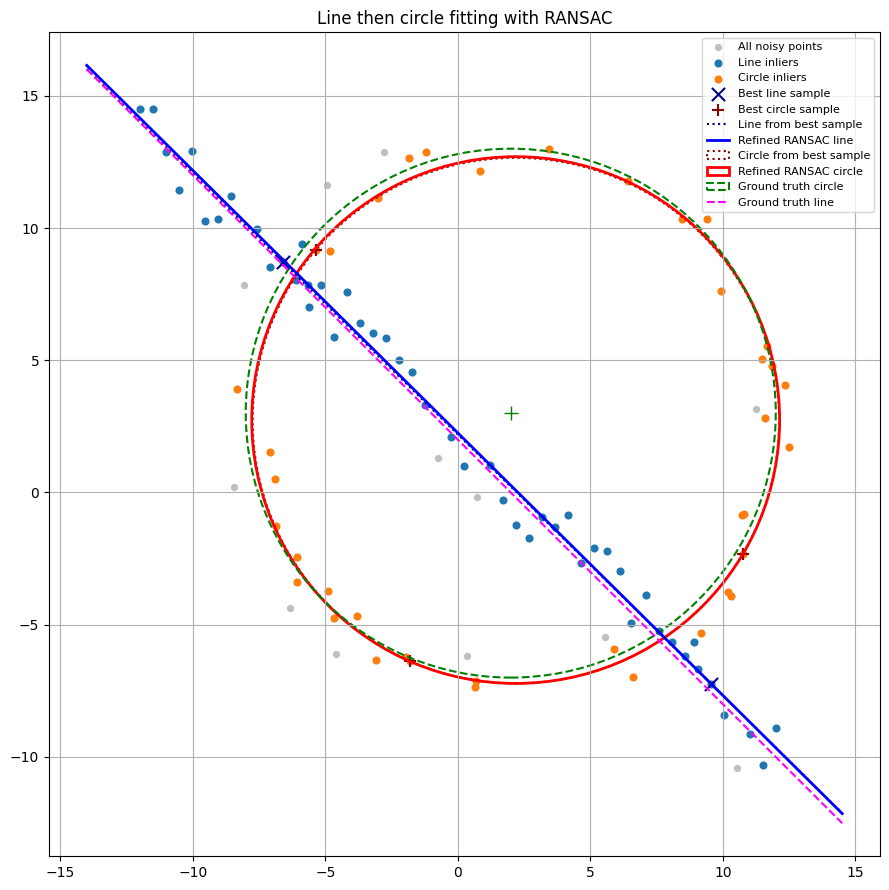

In [8]:
# Q2(b): Remove the line consensus, then use three-point RANSAC and radial error to find the circle.
# Q2(c): Plot the best sample hypotheses, refined models, ground truth, and both inlier sets.
def circle_from_three_points(points):
    """Return (cx, cy, radius) for a 3-point circle, or None if degenerate."""
    p1, p2, p3 = np.asarray(points, dtype=float)
    matrix = 2.0 * np.vstack((p2 - p1, p3 - p1))
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(matrix)) < 1e-8:
        return None
    center = np.linalg.solve(matrix, rhs)
    radius = float(np.linalg.norm(center - p1))
    if not np.isfinite(radius) or radius <= 0:
        return None
    return float(center[0]), float(center[1]), radius


def ransac_circle(points, threshold=0.8, min_inliers=38, iterations=4000, seed=1):
    """Three-point circle RANSAC with radial-error consensus."""
    random = np.random.default_rng(seed)
    best_model, best_mask, best_sample = None, None, None
    for _ in range(iterations):
        sample = random.choice(len(points), size=3, replace=False)
        model = circle_from_three_points(points[sample])
        if model is None:
            continue
        cx, cy, radius = model
        errors = np.abs(np.linalg.norm(points - np.array([cx, cy]), axis=1) - radius)
        mask = errors < threshold
        if best_mask is None or mask.sum() > best_mask.sum():
            best_model, best_mask, best_sample = model, mask, sample
    if best_mask is None or best_mask.sum() < min_inliers:
        raise RuntimeError("RANSAC did not find a circle with enough consensus points.")

    # Refine center and radius by minimizing radial residuals over the consensus set.
    from scipy.optimize import least_squares
    inlier_points = points[best_mask]
    fit = least_squares(
        lambda params: np.linalg.norm(inlier_points - params[:2], axis=1) - params[2],
        x0=np.asarray(best_model),
        bounds=([-np.inf, -np.inf, 1e-8], [np.inf, np.inf, np.inf]),
    )
    cx, cy, radius = fit.x
    return (float(cx), float(cy), float(radius)), best_mask, best_sample, best_model

circle_points = X[~line_inliers]
circle_model, circle_inliers_local, circle_sample, circle_sample_model = ransac_circle(
    circle_points, threshold=0.8, min_inliers=30, iterations=4000, seed=1
)
circle_inliers = np.zeros(len(X), dtype=bool)
circle_inliers[np.flatnonzero(~line_inliers)[circle_inliers_local]] = True
cx, cy, radius = circle_model
print(f"Circle: center=({cx:.3f}, {cy:.3f}), radius={radius:.3f}")
print(f"Circle consensus: {circle_inliers.sum()} / {len(circle_points)} line-removed points")
print(f"Three-point sample indices in line-removed set: {circle_sample}")

# Sample-derived models are drawn separately from the consensus-refined models.
line_sample_model = line_from_two_points(X[line_sample[0]], X[line_sample[1]])
def draw_line(ax, model, x_values, **kwargs):
    la, lb, ld = model
    if abs(lb) > 1e-8:
        ax.plot(x_values, (ld - la * x_values) / lb, **kwargs)
    else:
        ax.axvline(ld / la, **kwargs)

fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(X[:, 0], X[:, 1], s=18, color="0.75", label="All noisy points")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=23, color="tab:blue", label="Line inliers")
ax.scatter(X[circle_inliers, 0], X[circle_inliers, 1], s=23, color="tab:orange", label="Circle inliers")
ax.scatter(X[line_sample, 0], X[line_sample, 1], s=90, marker="x", color="navy", label="Best line sample")
original_circle_points = circle_points[circle_sample]
ax.scatter(original_circle_points[:, 0], original_circle_points[:, 1], s=85, marker="+", color="darkred", label="Best circle sample")
x_values = np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300)
draw_line(ax, line_sample_model, x_values, color="navy", linestyle=":", linewidth=1.5, label="Line from best sample")
draw_line(ax, line_model, x_values, color="blue", linewidth=2, label="Refined RANSAC line")
# The sample circle can be extremely large for near-collinear triplets; omit only if off-plot.
scx, scy, sr = circle_sample_model
if sr < 100:
    ax.add_patch(plt.Circle((scx, scy), sr, fill=False, color="darkred", linestyle=":", linewidth=1.5, label="Circle from best sample"))
ax.add_patch(plt.Circle((cx, cy), radius, fill=False, color="red", linewidth=2, label="Refined RANSAC circle"))
ax.add_patch(plt.Circle(tuple(circle_center_gt), circle_radius_gt, fill=False, color="green", linestyle="--", linewidth=1.5, label="Ground truth circle"))
ax.plot(*circle_center_gt, "+", color="green", markersize=10)
# Ground-truth line is included for visual comparison.
ax.plot(x_values, line_slope_gt * x_values + line_intercept_gt, color="magenta", linestyle="--", linewidth=1.5, label="Ground truth line")
ax.set_aspect("equal", adjustable="datalim")
ax.set_title("Line then circle fitting with RANSAC")
ax.grid(True)
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
q2_output = RESULTS_DIR / "question_2"
q2_output.mkdir(parents=True, exist_ok=True)
fig.savefig(q2_output / "line_circle_ransac.png", dpi=180, bbox_inches="tight")
plt.show()


### Question 2(d): Order of fitting

Fitting the circle first is possible with a suitable threshold and consensus size. However, the line points can support large-radius circle hypotheses, so fitting the line first usually leaves a cleaner set for circle estimation. The order can be reversed when each model is validated by its own consensus; neither order is guaranteed at every noise level.


# Question 3

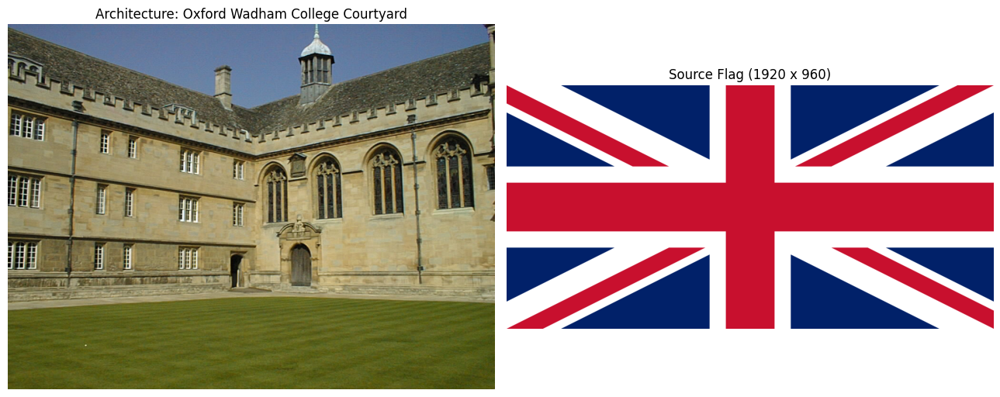

In [9]:
# Q3(a): Load the source flag and architecture image, then inspect both.
architecture_path = IMAGE_DIR / "wadham.jpg"
flag_path = IMAGE_DIR / "flag.png"

architecture_bgr = cv2.imread(str(architecture_path), cv2.IMREAD_COLOR)
flag_raw = cv2.imread(str(flag_path), cv2.IMREAD_UNCHANGED)

if architecture_bgr is None or flag_raw is None:
    raise FileNotFoundError(f"Could not load {architecture_path} or {flag_path}")

# Handle both 3-channel (BGR) and 4-channel (BGRA) flag images
if flag_raw.ndim == 3 and flag_raw.shape[2] == 4:
    flag_bgra = flag_raw
    flag_rgb = cv2.cvtColor(flag_bgra[:, :, :3], cv2.COLOR_BGR2RGB)
elif flag_raw.ndim == 3 and flag_raw.shape[2] == 3:
    alpha_channel = np.full((flag_raw.shape[0], flag_raw.shape[1], 1), 255, dtype=np.uint8)
    flag_bgra = np.concatenate([flag_raw, alpha_channel], axis=-1)
    flag_rgb = cv2.cvtColor(flag_raw, cv2.COLOR_BGR2RGB)
else:
    raise ValueError(f"Unexpected flag image shape: {flag_raw.shape}")

architecture_rgb = cv2.cvtColor(architecture_bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(architecture_rgb)
axes[0].set_title("Architecture: Oxford Wadham College Courtyard")
axes[0].axis("off")
axes[1].imshow(flag_rgb)
axes[1].set_title(f"Source Flag ({flag_raw.shape[1]} x {flag_raw.shape[0]})")
axes[1].axis("off")
plt.tight_layout()
plt.show()


Using calibrated preset for 'wadham_left_wall':
[[147. 208.]
 [516. 292.]
 [520. 520.]
 [135. 518.]]
[Placement 1 (Left Courtyard Facade - Figure 2 Replication)] -> Saved: C:\Users\Jaindu Samaranayaka\Documents\Semester_5\CV\fitting and alignment git\results\question_3\wadham_flag_1.png


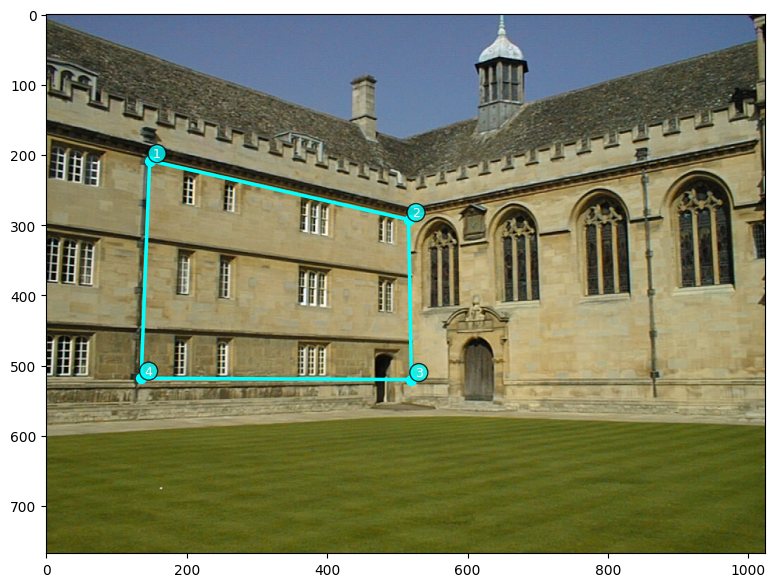

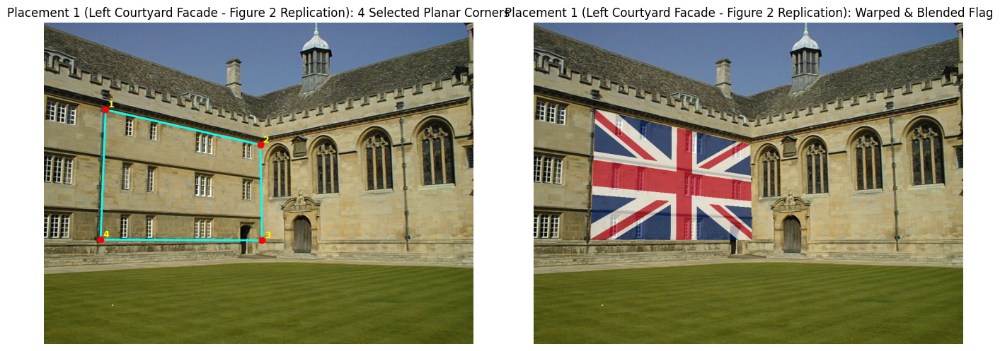

Using calibrated preset for 'wadham_lawn':
[[150. 600.]
 [874. 600.]
 [980. 750.]
 [ 44. 750.]]
[Placement 2 (Courtyard Lawn - Ceremonial Event Display)] -> Saved: C:\Users\Jaindu Samaranayaka\Documents\Semester_5\CV\fitting and alignment git\results\question_3\wadham_flag_2.png


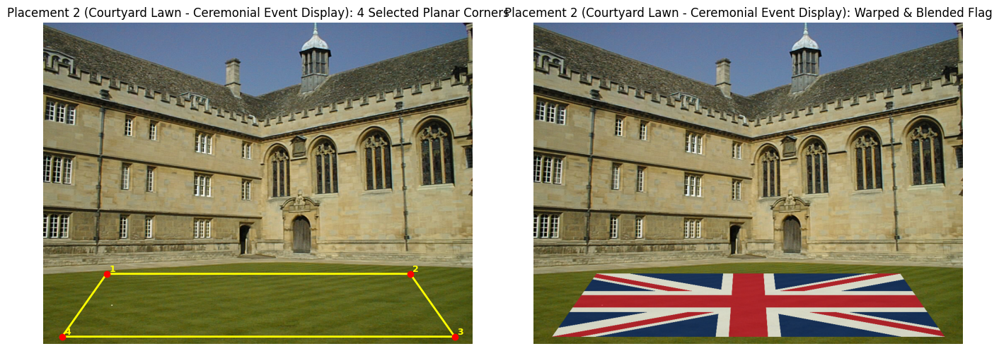

Using calibrated preset for 'wadham_right_wall':
[[520. 295.]
 [960. 235.]
 [960. 680.]
 [520. 520.]]
[Placement 3 (Right Chapel Wall Facade)] -> Saved: C:\Users\Jaindu Samaranayaka\Documents\Semester_5\CV\fitting and alignment git\results\question_3\wadham_flag_3.png


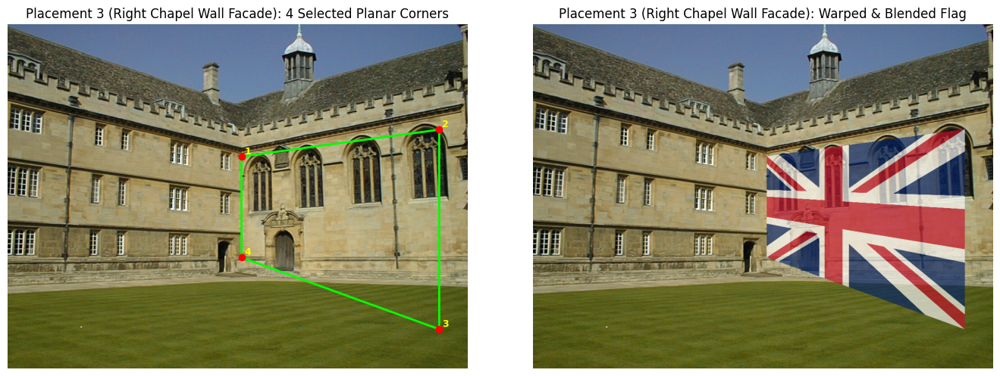

<Figure size 640x480 with 0 Axes>

Saved corners overlay to: C:\Users\Jaindu Samaranayaka\Documents\Semester_5\CV\fitting and alignment git\results\question_3\wadham_corners_overlay.png


In [10]:
# Q3(b-d): Corner selection, homography estimation, perspective warping, and alpha blending.
# Solves the live interactive corner selection issue in IDEs:
# 1) Set INTERACTIVE_SELECTION = True to launch a native interactive OpenCV window.
# 2) Set INTERACTIVE_SELECTION = False (default) to run seamlessly using pre-calibrated planar surface corners.
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.corner_selector import CALIBRATED_CORNERS, get_corners
from src.q3_homography_warper import compute_homography_and_warp, blend_images

result_dir_q3 = RESULTS_DIR / "question_3"
result_dir_q3.mkdir(parents=True, exist_ok=True)

# Toggle live interactive GUI window (False by default for reliable notebook execution in IDEs)
INTERACTIVE_SELECTION = False

placements_config = [
    {
        "id": 1,
        "key": "wadham_left_wall",
        "name": "Placement 1 (Left Courtyard Facade - Figure 2 Replication)",
        "alpha": 0.65,
        "color": "cyan",
    },
    {
        "id": 2,
        "key": "wadham_lawn",
        "name": "Placement 2 (Courtyard Lawn - Ceremonial Event Display)",
        "alpha": 0.75,
        "color": "yellow",
    },
    {
        "id": 3,
        "key": "wadham_right_wall",
        "name": "Placement 3 (Right Chapel Wall Facade)",
        "alpha": 0.65,
        "color": "lime",
    },
]

height, width = architecture_bgr.shape[:2]
fig_overlay, ax_overlay = plt.subplots(figsize=(11, 7))
ax_overlay.imshow(architecture_rgb)

for p in placements_config:
    p_num = p["id"]
    p_name = p["name"]
    p_key = p["key"]
    p_alpha = p["alpha"]
    p_color = p["color"]

    # Select corners (live interactive OpenCV window if INTERACTIVE_SELECTION=True, else calibrated preset)
    dst_corners = get_corners(
        architecture_bgr,
        preset_key=p_key,
        interactive=INTERACTIVE_SELECTION,
        window_title=f"Corner Selection: {p_name}",
    )

    # Compute homography and warp flag
    warped, mask, H = compute_homography_and_warp(flag_bgra, dst_corners, (height, width))
    blended = blend_images(architecture_bgr, warped, mask, alpha_blend=p_alpha)

    # Save output image
    output_path = result_dir_q3 / f"wadham_flag_{p_num}.png"
    cv2.imwrite(str(output_path), blended)
    print(f"[{p_name}] -> Saved: {output_path}")

    # Draw on summary overlay
    poly = np.vstack([dst_corners, dst_corners[0:1]])
    ax_overlay.plot(poly[:, 0], poly[:, 1], color=p_color, linewidth=2.5, label=f"P{p_num}: {p_key}")
    for idx_pt, pt in enumerate(dst_corners):
        ax_overlay.plot(pt[0], pt[1], "o", color=p_color, markersize=7)
        ax_overlay.text(pt[0] + 5, pt[1] - 5, f"{idx_pt+1}", color="white", fontsize=9,
                        bbox=dict(boxstyle="circle,pad=0.2", facecolor=p_color, alpha=0.8))

    # Display individual result side-by-side
    fig_res, axes_res = plt.subplots(1, 2, figsize=(14, 5))
    axes_res[0].imshow(architecture_rgb)
    axes_res[0].plot(poly[:, 0], poly[:, 1], color=p_color, linewidth=2)
    for idx_pt, pt in enumerate(dst_corners):
        axes_res[0].plot(pt[0], pt[1], "ro", markersize=6)
        axes_res[0].text(pt[0] + 6, pt[1] - 6, f"{idx_pt+1}", color="yellow", fontsize=9, weight="bold")
    axes_res[0].set_title(f"{p_name}: 4 Selected Planar Corners")
    axes_res[0].axis("off")

    axes_res[1].imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
    axes_res[1].set_title(f"{p_name}: Warped & Blended Flag")
    axes_res[1].axis("off")
    plt.tight_layout()
    plt.show()

ax_overlay.set_title("Wadham College: Calibrated Planar Placement Boundaries", fontsize=12)
ax_overlay.legend(loc="lower right", fontsize=9)
ax_overlay.axis("off")
plt.tight_layout()
overlay_path = result_dir_q3 / "wadham_corners_overlay.png"
fig_overlay.savefig(overlay_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved corners overlay to: {overlay_path}")


## Question 4

Align each PCB to `AECC1.jpg`, then compare the aligned grayscale images.

### Question 4(a): Detect SIFT features in the reference template

In [11]:
# Q4(a): Load the AECC1 reference and extract SIFT features.
pcb_dir = IMAGE_DIR / "pcbs"
template_path = pcb_dir / "AECC1.jpg"
result_dir_q4 = RESULTS_DIR / "question_4"
result_dir_q4.mkdir(parents=True, exist_ok=True)
template_bgr = cv2.imread(str(template_path), cv2.IMREAD_COLOR)
if template_bgr is None:
    raise FileNotFoundError(f"Could not load template: {template_path}")
template_gray = cv2.cvtColor(template_bgr, cv2.COLOR_BGR2GRAY)
sift = cv2.SIFT_create()
template_keypoints, template_descriptors = sift.detectAndCompute(template_gray, None)
print(f"AECC1 template SIFT features: {len(template_keypoints)}")


AECC1 template SIFT features: 14272


### Question 4(b-d): Match features, estimate a RANSAC homography, and compute alignment differences

In [12]:
# Q4(b): Match SIFT descriptors with a ratio test.
# Q4(c): Estimate the PCB-to-template homography with RANSAC and draw inlier matches.
# Q4(d): Warp each PCB and compute its absolute grayscale difference from the template.
matcher = cv2.BFMatcher(cv2.NORM_L2)

def align_and_compare(pcb_name):
    pcb_path = pcb_dir / f"{pcb_name}.jpg"
    pcb_bgr = cv2.imread(str(pcb_path), cv2.IMREAD_COLOR)
    if pcb_bgr is None:
        raise FileNotFoundError(f"Could not load PCB image: {pcb_path}")
    pcb_gray = cv2.cvtColor(pcb_bgr, cv2.COLOR_BGR2GRAY)
    pcb_keypoints, pcb_descriptors = sift.detectAndCompute(pcb_gray, None)
    if template_descriptors is None or pcb_descriptors is None:
        print(f"Skipping {pcb_name}: no SIFT descriptors found.")
        return None
    pairs = matcher.knnMatch(template_descriptors, pcb_descriptors, k=2)
    good_matches = [m for pair in pairs if len(pair) == 2 for m, n in [pair] if m.distance < 0.75 * n.distance]
    if len(good_matches) < 4:
        print(f"Skipping {pcb_name}: only {len(good_matches)} reliable matches.")
        return None
    template_pts = np.float32([template_keypoints[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    pcb_pts = np.float32([pcb_keypoints[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    homography, inlier_mask = cv2.findHomography(pcb_pts, template_pts, cv2.RANSAC, 5.0)
    if homography is None or inlier_mask is None:
        print(f"Skipping {pcb_name}: RANSAC could not estimate a homography.")
        return None
    matches_image = cv2.drawMatches(
        template_bgr, template_keypoints, pcb_bgr, pcb_keypoints, good_matches, None,
        matchColor=(0, 255, 0), singlePointColor=(255, 0, 0),
        matchesMask=inlier_mask.ravel().tolist(), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    h, w = template_gray.shape
    aligned = cv2.warpPerspective(pcb_bgr, homography, (w, h))
    difference = cv2.absdiff(template_gray, cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY))
    return matches_image, aligned, difference, len(good_matches), int(inlier_mask.sum())


### Question 4(e): Process each PCB and explain the component differences

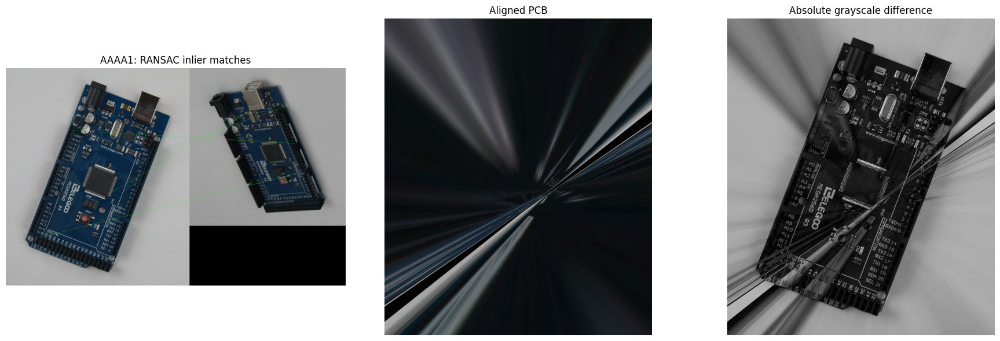

AAAA1: 395 ratio-test matches, 8 RANSAC inliers


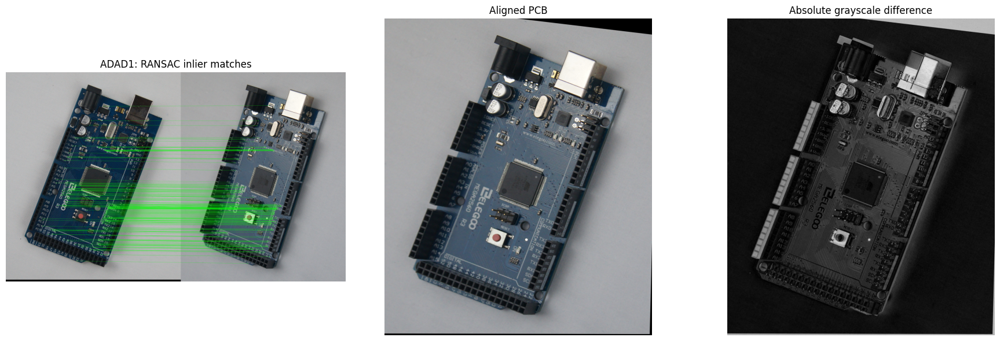

ADAD1: 655 ratio-test matches, 226 RANSAC inliers


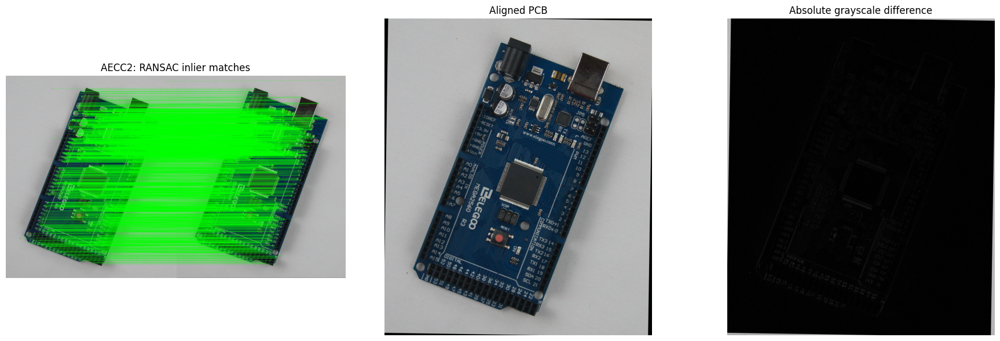

AECC2: 4606 ratio-test matches, 3951 RANSAC inliers


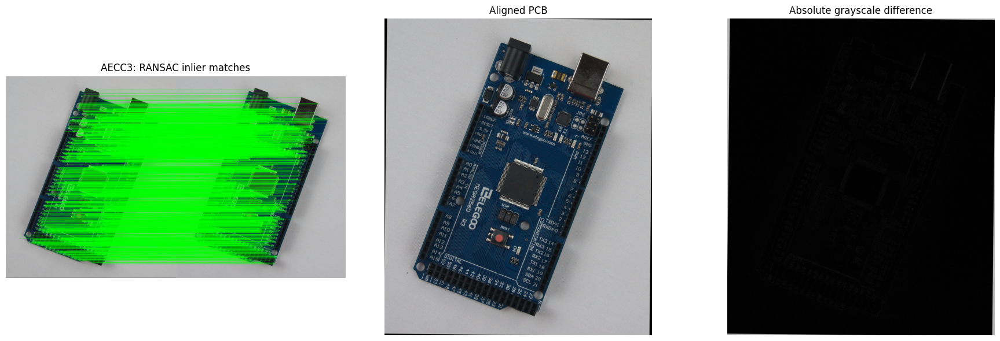

AECC3: 5652 ratio-test matches, 4997 RANSAC inliers


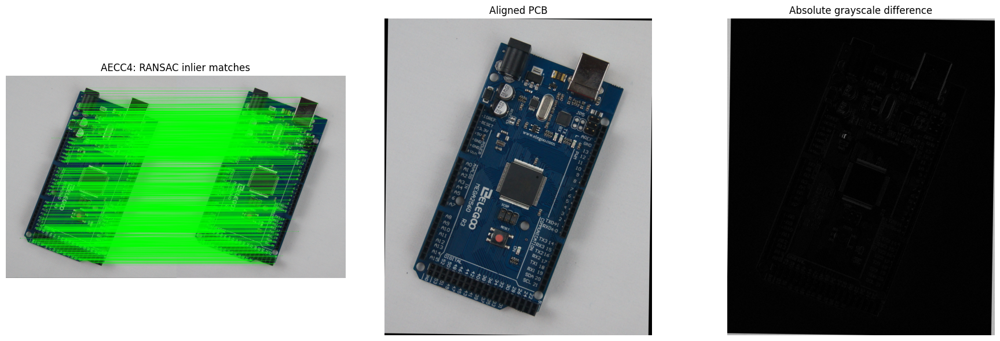

AECC4: 4009 ratio-test matches, 3424 RANSAC inliers
Saved PCB comparisons to C:\Users\Jaindu Samaranayaka\Documents\Semester_5\CV\fitting and alignment git\results\question_4


In [13]:
# Q4(e): Run alignment for every PCB except the AECC1 reference itself.
pcb_names = ["AAAA1", "ADAD1", "AECC2", "AECC3", "AECC4"]
for pcb_name in pcb_names:
    result = align_and_compare(pcb_name)
    if result is None:
        continue
    matches_image, aligned, difference, match_count, inlier_count = result
    cv2.imwrite(str(result_dir_q4 / f"{pcb_name}_matches.png"), matches_image)
    cv2.imwrite(str(result_dir_q4 / f"{pcb_name}_aligned.png"), aligned)
    cv2.imwrite(str(result_dir_q4 / f"{pcb_name}_difference.png"), difference)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(cv2.cvtColor(matches_image, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"{pcb_name}: RANSAC inlier matches")
    axes[0].axis("off")
    axes[1].imshow(cv2.cvtColor(aligned, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Aligned PCB")
    axes[1].axis("off")
    axes[2].imshow(difference, cmap="gray", vmin=0, vmax=255)
    axes[2].set_title("Absolute grayscale difference")
    axes[2].axis("off")
    plt.tight_layout()
    plt.show()
    print(f"{pcb_name}: {match_count} ratio-test matches, {inlier_count} RANSAC inliers")

print(f"Saved PCB comparisons to {result_dir_q4}")


**Answer to Question 4(e):** The USB Type B port, capacitors, and reset button have high difference values because their physical positions, shapes, or presence differ from the AECC1 reference across board variants. Homography corrects the overall planar viewpoint and alignment, but cannot make distinct components match. Lighting and small registration errors can also contribute around component edges.

### Question 3 Discussion: Homography Formulation & Placement Rationale

**Mathematical Formulation:**
A planar homography is a 2D projective transformation represented by an invertible $3 \times 3$ matrix $\mathbf{H}$ with 8 degrees of freedom (defined up to scale):
$$\mathbf{x}' \sim \mathbf{H}\mathbf{x} \implies \begin{bmatrix} x' \\ y' \\ 1 \end{bmatrix} \sim \begin{bmatrix} h_{11} & h_{12} & h_{13} \\ h_{21} & h_{22} & h_{23} \\ h_{31} & h_{32} & h_{33} \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$
Each 2D point correspondence provides two independent linear equations:
$$x'_i = \frac{h_{11}x_i + h_{12}y_i + h_{13}}{h_{31}x_i + h_{32}y_i + h_{33}}, \quad y'_i = \frac{h_{21}x_i + h_{22}y_i + h_{23}}{h_{31}x_i + h_{32}y_i + h_{33}}$$
Hence, four non-collinear point correspondences are required to construct the $8 \times 9$ system $\mathbf{A}\mathbf{h} = \mathbf{0}$ solved via Direct Linear Transformation (DLT) using SVD.

**Non-Technical Rationale for Placements:**
- **Placement 1 (Left Courtyard Wall):** Accurately replicates Figure 2 of the assignment brief, superimposing the British flag onto the historic Oxford college residential facade between architectural mouldings.
- **Placement 2 (Courtyard Lawn):** Simulates a massive ceremonial ground banner on the manicured lawn for university celebrations, demonstrating homography handling extreme ground-plane perspective foreshortening.
- **Placement 3 (Right Chapel Wall):** Places the flag on the orthogonal chapel facade, illustrating how planar homography conforms to perspective convergence across multi-planar building architecture.
